# 5. QuEST backend simulation

In the previous tutorial, we estimated the fault-tolerant resources of quantum phase estimation (QPE) with the Qualtran backend. In this tutorial, we dispatch the same `QPESpec` calculations to the QuEST backend instead. QuEST runs a state-vector simulation of the circuit, so we can check that each method actually recovers the correct energy, and measure how expensive each method is to simulate on a classical computer.

## 5.1. Methods available in the QuEST backend

The QuEST backend supports two phase estimation algorithms:

- **Textbook QPE** (`PhaseEstimation.Textbook`): Uses a register of $m$ ancilla qubits, applies controlled $U^{2^k}$ from the $k$-th ancilla, and reads out the phase with an inverse quantum Fourier transform. We take the most likely outcome of the ancilla register.
- **Kitaev QPE** (`PhaseEstimation.Kitaev`): Uses a single ancilla qubit and estimates the phase one bit at a time over $m$ rounds, from the expectation values $\langle X \rangle$ and $\langle Y \rangle$ of the ancilla. It applies the same controlled $U^{2^k}$ operations as textbook QPE, but needs $m - 1$ fewer qubits.

Both algorithms work with Trotterisation and QDRIFT. Qubitisation is currently only available with textbook QPE. See the previous tutorial for a description of the three simulation methods.

The way we convert the measured phase $\phi \in [-1/2, 1/2)$ into an energy depends on the simulation method:

- **Trotterisation and QDRIFT** approximate $U = e^{-iHt}$ with $t = \pi/\lambda$, so the energy is $E = 2\pi\phi/t$.
- **Qubitisation** builds a walk operator with eigenphases $\pm\arccos(E/\lambda)$, so the energy is $E = \lambda\cos(2\pi\phi)$.

## 5.2. Setup

We use the minimal-basis hydrogen molecule ($\mathrm{H}_2$, 2 spatial orbitals, 4 qubits) from `data/hydrogen.fcidump` as our test system, with the Jordan–Wigner mapping and the Hartree–Fock (HF) initial state. We compare all five (QPE, simulation) combinations supported by the QuEST backend.

A state-vector simulation stores $2^n$ complex amplitudes for $n$ qubits, so the cost grows quickly with the number of qubits and gates. We therefore keep the number of phase bits small, and the whole notebook takes a few minutes to run.

In [1]:
import time
from math import cos, pi
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.figure import Figure
from random_hamiltonian import generate_random_sq_hamiltonian

from quiche import QPESpec
from quiche.bindings.quest_bindings import QuESTEnv, Qureg
from quiche.chemistry import HartreeFockState, get_jw_state
from quiche.core import (
    ElectronicHamiltonian,
    Errors,
    Mapping,
    PhaseEstimation,
    Simulation,
)
from quiche.io import fcidump

# Fixed settings for the whole study.
MAPPING = Mapping.JordanWigner
SEED = 1
CHEMICAL_ACCURACY = 1.6e-3  # Hartree

# QuEST can only be initialised once per process, so share one environment.
QUEST_ENV = QuESTEnv()

# (QPE, simulation) combinations supported by the QuEST backend.
METHODS = [
    (PhaseEstimation.Textbook, Simulation.Trotter),
    (PhaseEstimation.Textbook, Simulation.QDRIFT),
    (PhaseEstimation.Textbook, Simulation.Qubitised),
    (PhaseEstimation.Kitaev, Simulation.Trotter),
    (PhaseEstimation.Kitaev, Simulation.QDRIFT),
]

# Colour and marker by simulation method, line style by QPE algorithm.
COLORS = {
    Simulation.Trotter.value: "tab:blue",
    Simulation.QDRIFT.value: "tab:orange",
    Simulation.Qubitised.value: "tab:green",
}
MARKERS = {
    Simulation.Trotter.value: "o",
    Simulation.QDRIFT.value: "s",
    Simulation.Qubitised.value: "^",
}
LINESTYLES = {PhaseEstimation.Textbook.value: "-", PhaseEstimation.Kitaev.value: "--"}

In [2]:
# Load the H2 Hamiltonian and map it to qubits.
sq_ham = fcidump.read("data/hydrogen.fcidump")
h2 = sq_ham.to_qubit_hamiltonian(mapping=MAPPING)
h2_hf = HartreeFockState.closed_shell(
    num_electrons=sq_ham.num_electrons, num_spin_orbitals=h2.paulis.num_qubits
)

print("Number of qubits:", h2.paulis.num_qubits)
print("Number of Pauli terms:", h2.paulis.num_words)
print("1-norm:", h2.paulis.lam)

Number of qubits: 4
Number of Pauli terms: 14
1-norm: 1.9839887941943157


To measure the accuracy of each method, we need the exact energy. We diagonalise the Hamiltonian matrix restricted to basis states with the correct number of electrons; the Jordan–Wigner mapping conserves the number of 1s in the bitstring. QPE projects the initial state onto an eigenstate with probability equal to their overlap, so we also compute the overlap of the HF state with each eigenstate.

In [3]:
def exact_spectrum(
    ham: ElectronicHamiltonian, hf: HartreeFockState
) -> tuple[np.ndarray, np.ndarray]:
    """Eigenvalues in the HF electron-number sector and their overlaps with HF."""
    n = ham.paulis.num_qubits
    # to_matrix() puts qubit 0 in the most significant bit.
    bits = get_jw_state(hf.occupation)
    hf_index = sum(int(b) << (n - 1 - i) for i, b in enumerate(bits))

    sector = [i for i in range(2**n) if i.bit_count() == hf.num_electrons]
    matrix = ham.paulis.to_matrix()[np.ix_(sector, sector)]
    energies, states = np.linalg.eigh(matrix)
    overlaps = np.abs(states[sector.index(hf_index), :]) ** 2
    return energies, overlaps


h2_energies, h2_overlaps = exact_spectrum(h2, h2_hf)
h2_exact = h2_energies[0]
print(f"Exact ground state energy: {h2_exact:.6f} Ha")
print(f"HF overlap with the ground state: {h2_overlaps[0]:.4f}")

Exact ground state energy: -1.137274 Ha
HF overlap with the ground state: 0.9873


## 5.3. Metrics

For each calculation, we build the QuEST routine with `QPESpec.to_quest()`, run it on a fresh `Qureg`, and record:

- **Energy error**: $|E_{\mathrm{QPE}} - E_{\mathrm{exact}}|$, compared with chemical accuracy ($1.6\times10^{-3}$ Ha).
- **Simulated qubits** and **state-vector memory**: QuEST stores $2^n$ double-precision complex amplitudes, i.e. $16 \times 2^n$ bytes.
- **Wall-clock time**: The time taken by the simulation.

The QuEST routines act on the data qubits, the QPE ancillas and, for qubitisation, the index ancillas. `spec.num_qubits` also counts the phase-gradient ancillas that the Qualtran circuit needs for its PREPARE oracle, which the state-vector simulation never touches. We allocate only the qubits that QuEST uses: for $\mathrm{H}_2$ with qubitisation, this avoids a state vector $2^{13}$ times larger than necessary.

In [4]:
def run_qpe(
    ham: ElectronicHamiltonian,
    hf: HartreeFockState,
    algorithm: PhaseEstimation,
    simulation: Simulation,
    errors: Errors,
) -> dict[str, Any]:
    """Run a QPE calculation in QuEST and return the energy and simulation cost."""
    spec = QPESpec(
        hamiltonian=ham,
        state_prep=hf,
        algorithm=algorithm,
        simulation=simulation,
        error_budget=errors,
        seed=SEED,
    )
    routine = spec.to_quest()

    # Data qubits, QPE ancillas and qubitisation index ancillas only.
    num_qubits = spec.num_data + spec.num_qpe_ancillas + spec.num_index_ancillas
    start = time.perf_counter()
    qureg = Qureg(num_qubits)
    results = routine.evaluate(qureg)

    phase = results[-1]
    runtime = time.perf_counter() - start
    qureg.__del__()  # clean up the Qureg

    if simulation == Simulation.Qubitised:
        energy = cos(2 * pi * phase) * ham.paulis.lam
    else:
        energy = phase * 2 * pi / spec.time

    # Textbook QPE uses one ancilla per phase bit, Kitaev QPE one round per bit.
    if algorithm == PhaseEstimation.Kitaev:
        phase_bits = spec.num_rounds
    else:
        phase_bits = spec.num_qpe_ancillas

    return {
        "qpe": algorithm.value,
        "simulation": simulation.value,
        "phase_bits": phase_bits,
        "qubits": num_qubits,
        "memory_mb": 16 * 2**num_qubits / 2**20,
        "runtime_s": runtime,
        "energy": energy,
    }


def plot_methods(
    df: pd.DataFrame, x: str, metrics: list[tuple[str, str, bool]], xlabel: str
) -> tuple[Figure, np.ndarray]:
    """Plot each metric against x, with one line per (QPE, simulation) method."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4.2))
    for ax, (metric, label, logy) in zip(axes, metrics, strict=True):
        for algorithm, simulation in METHODS:
            group = df[
                (df["qpe"] == algorithm.value) & (df["simulation"] == simulation.value)
            ]
            ax.plot(
                group[x],
                group[metric],
                label=f"{algorithm.value} + {simulation.value}",
                color=COLORS[simulation.value],
                marker=MARKERS[simulation.value],
                linestyle=LINESTYLES[algorithm.value],
            )
        ax.set_xticks(sorted(df[x].unique()))
        ax.set_xlabel(xlabel)
        ax.set_ylabel(label)
        if logy:
            ax.set_yscale("log")
        ax.grid(visible=True, which="major", alpha=0.3)
    fig.tight_layout()
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=len(METHODS)
    )
    return fig, axes

## 5.4. Accuracy and cost vs. phase precision

First, we run every method on $\mathrm{H}_2$ with an increasing number of phase bits $m$. In QUICHE, $m$ is set by the `estimation` and `overlap` entries of the error budget, $m = \lceil\log_2(1/\epsilon_{\mathrm{est}})\rceil + \lceil\log_2(1/\mathrm{overlap})\rceil + 4$. We fix the simulation error at $\epsilon_{\mathrm{sim}} = 10^{-2}$.

In [5]:
rows = []
for eps_est in [1 / 2, 1 / 4, 1 / 8, 1 / 16]:
    errors = Errors(
        estimation=eps_est,
        simulation=1e-2,
        rotations=1e-3,
        state_prep=1e-3,
        overlap=0.9,
    )
    for algorithm, simulation in METHODS:
        rows.append(run_qpe(h2, h2_hf, algorithm, simulation, errors))

df_bits = pd.DataFrame(rows)
df_bits["error"] = (df_bits["energy"] - h2_exact).abs()
df_bits.set_index(["phase_bits", "qpe", "simulation"])

qubits  memory_mb  runtime_s    energy  \
phase_bits qpe      simulation                                           
6          textbook trotter         10   0.015625   8.387202 -1.115994   
                    qdrift          10   0.015625   6.802200 -1.115994   
                    qubitised       14   0.250000   0.220496 -1.102245   
           kitaev   trotter          5   0.000488   0.062150 -1.137195   
                    qdrift           5   0.000488   0.163096 -1.127013   
7          textbook trotter         11   0.031250  14.971791 -1.146994   
                    qdrift          11   0.031250  13.781305 -1.146994   
                    qubitised       15   0.500000   0.409101 -1.102245   
           kitaev   trotter          5   0.000488   0.128558 -1.137199   
                    qdrift           5   0.000488   0.321377 -1.129117   
8          textbook trotter         12   0.062500  29.346690 -1.131494   
                    qdrift          12   0.062500  26.905926 -1.146994   
                    qubitised       16   1.000000   0.862392 -1.142397   
           kitaev   trotter          5   0.000488   0.263145 -1.137211   
                    qdrift           5   0.000488   0.649939 -1.134373   
9          textbook trotter         13   0.125000  58.846414 -1.139244   
                    qdrift          13   0.125000  56.210820 -1.139244   
                    qubitised       17   2.000000   1.744754 -1.142397   
           kitaev   trotter          5   0.000488   0.524333 -1.137251   
                    qdrift           5   0.000488   1.288919 -1.138052   

                                   error  
phase_bits qpe      simulation            
6          textbook trotter     0.021281  
                    qdrift      0.021281  
                    qubitised   0.035029  
           kitaev   trotter     0.000079  
                    qdrift      0.010261  
7          textbook trotter     0.009719  
                    qdrift      0.009719  
                    qubitised   0.035029  
           kitaev   trotter     0.000076  
                    qdrift      0.008158  
8          textbook trotter     0.005781  
                    qdrift      0.009719  
                    qubitised   0.005123  
           kitaev   trotter     0.000063  
                    qdrift      0.002901  
9          textbook trotter     0.001969  
                    qdrift      0.001969  
                    qubitised   0.005123  
           kitaev   trotter     0.000024  
                    qdrift      0.000777

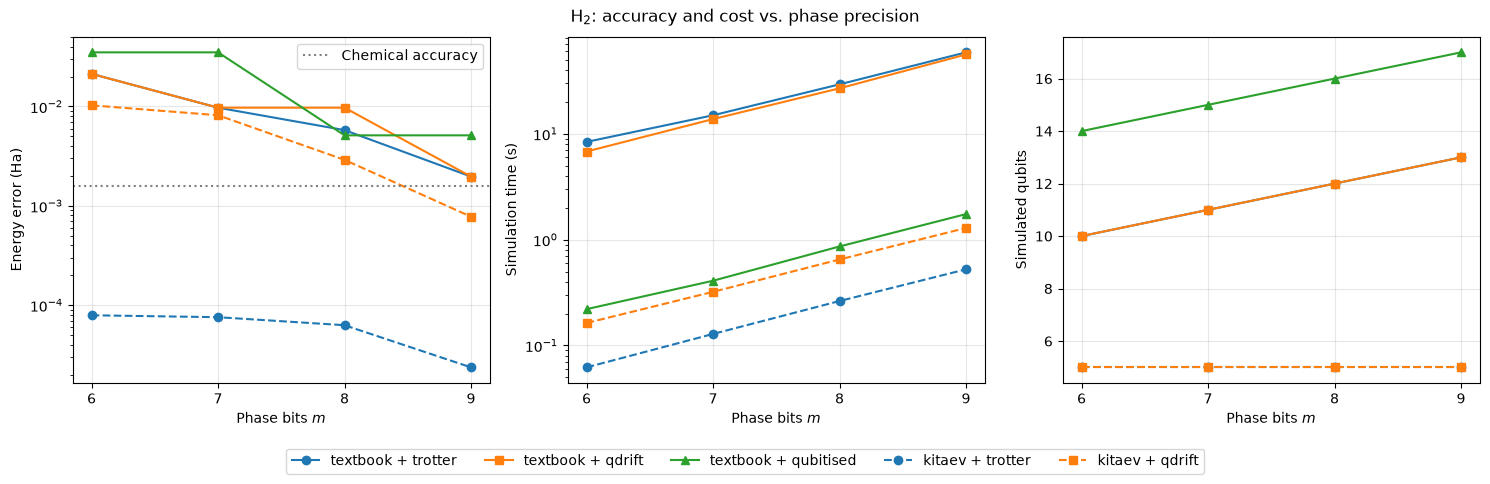

In [6]:
fig, axes = plot_methods(
    df_bits,
    x="phase_bits",
    xlabel="Phase bits $m$",
    metrics=[
        ("error", "Energy error (Ha)", True),
        ("runtime_s", "Simulation time (s)", True),
        ("qubits", "Simulated qubits", False),
    ],
)
chem = axes[0].axhline(CHEMICAL_ACCURACY, color="grey", linestyle=":")
axes[0].legend([chem], ["Chemical accuracy"])
fig.suptitle(r"H$_2$: accuracy and cost vs. phase precision", y=1.03)
plt.show()

A few things to notice:

- **Textbook QPE is limited by its phase grid.** Reading out a single $m$-bit outcome rounds the phase to a multiple of $2^{-m}$. For Trotterisation and QDRIFT, this is an energy grid with spacing $2\lambda/2^m$: about $0.062$ Ha at $m = 6$ and $0.0078$ Ha at $m = 9$. Both methods often round to the same grid point and give the same energy, so their lines overlap. Neither reaches chemical accuracy by $m = 9$.
- **Qubitisation** has no simulation error, but its energy $E = \lambda\cos(2\pi\phi)$ makes the energy grid about $\pi\sin(2\pi\phi) \approx 2.6$ times coarser for $\mathrm{H}_2$. That's why its error drops in steps.
- **Kitaev QPE** is far more accurate here. The QuEST backend computes $\langle X\rangle$ and $\langle Y\rangle$ exactly from the state vector, so the phase estimate isn't rounded to a grid. The Kitaev + Trotter error of $2\times10^{-5}$ to $8\times10^{-5}$ Ha is the actual Trotter error, well below $\epsilon_{\mathrm{sim}}$. Kitaev + QDRIFT is less accurate, because each power of $U$ uses a fresh random sample of terms. On real hardware, these expectation values would be estimated from a finite number of measurement shots, so the Kitaev results are optimistic.
- **Every extra phase bit doubles the simulation time** for all methods, since QPE applies $U^{2^k}$ for $k$ up to $m - 1$. Textbook QPE also adds one qubit per bit; Kitaev QPE always uses 5 qubits.
- **Textbook qubitisation is about $30$ to $40\times$ faster** than textbook Trotterisation and QDRIFT, even though it simulates 4 more qubits (a $16\times$ larger state vector). Each walk step applies the 14 Pauli terms once, plus PREPARE. In contrast, each $U$ costs 56 Trotter steps of 28 rotations each, or 1974 QDRIFT rotations.
- **Kitaev QPE is about $40\times$ (QDRIFT) to over $100\times$ (Trotterisation) cheaper to simulate** than textbook QPE with the same simulation method, because its state vector is $2^5$ amplitudes instead of $2^{10}$ to $2^{13}$.

## 5.5. Cost vs. system size

Next, we fix the number of phase bits at $m = 6$ and increase the system size with the random Hamiltonians from `random_hamiltonian.py` (`n_orb` from 1 to 3, with 2 electrons). These Hamiltonians are not real molecules, and the HF state can have a small overlap with the ground state. QPE then returns a different eigenstate, so here we only compare the simulation cost.

In [7]:
errors = Errors(
    estimation=1 / 2, simulation=1e-2, rotations=1e-3, state_prep=1e-3, overlap=0.9
)

rng = np.random.default_rng(SEED)
rows = []
for n_orb in [1, 2, 3]:
    sq_ham = generate_random_sq_hamiltonian(n_orb=n_orb, n_elec=2, rng=rng)
    ham = sq_ham.to_qubit_hamiltonian(mapping=MAPPING)
    hf = HartreeFockState.closed_shell(num_electrons=2, num_spin_orbitals=2 * n_orb)
    for algorithm, simulation in METHODS:
        row = run_qpe(ham, hf, algorithm, simulation, errors)
        rows.append({"n_orb": n_orb, "num_terms": ham.paulis.num_words, **row})

df_size = pd.DataFrame(rows)
df_size.set_index(["n_orb", "qpe", "simulation"])

num_terms  phase_bits  qubits  memory_mb  \
n_orb qpe      simulation                                             
1     textbook trotter             3           6       8   0.003906   
               qdrift              3           6       8   0.003906   
               qubitised           3           6      10   0.015625   
      kitaev   trotter             3           6       3   0.000122   
               qdrift              3           6       3   0.000122   
2     textbook trotter            26           6      10   0.015625   
               qdrift             26           6      10   0.015625   
               qubitised          26           6      15   0.500000   
      kitaev   trotter            26           6       5   0.000488   
               qdrift             26           6       5   0.000488   
3     textbook trotter           117           6      12   0.062500   
               qdrift            117           6      12   0.062500   
               qubitised         117           6      19   8.000000   
      kitaev   trotter           117           6       7   0.001953   
               qdrift            117           6       7   0.001953   

                           runtime_s        energy  
n_orb qpe      simulation                           
1     textbook trotter      1.274890 -1.867495e+00  
               qdrift       5.547982 -1.867495e+00  
               qubitised    0.049187 -1.805297e+00  
      kitaev   trotter      0.011780 -1.882858e+00  
               qdrift       0.143102 -1.869657e+00  
2     textbook trotter     18.306989  0.000000e+00  
               qdrift       7.647289  0.000000e+00  
               qubitised    0.435648  3.199091e-16  
      kitaev   trotter      0.164029  1.781148e-02  
               qdrift       0.167702 -1.551801e-02  
3     textbook trotter     95.524386 -9.914572e-01  
               qdrift      10.612720 -9.914572e-01  
               qubitised    2.022123 -1.554877e+00  
      kitaev   trotter      0.870166 -8.731614e-01  
               qdrift       0.197036 -9.379173e-01

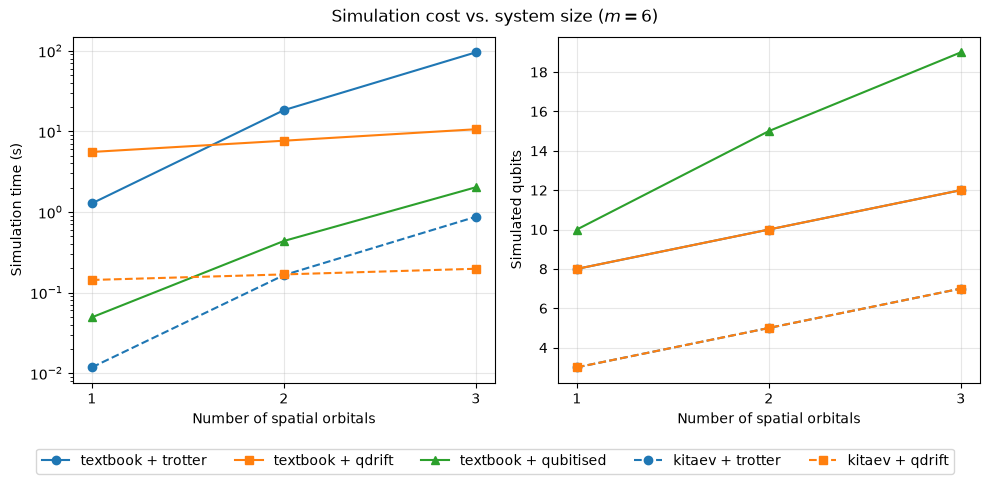

In [8]:
fig, axes = plot_methods(
    df_size,
    x="n_orb",
    xlabel="Number of spatial orbitals",
    metrics=[
        ("runtime_s", "Simulation time (s)", True),
        ("qubits", "Simulated qubits", False),
    ],
)
fig.suptitle("Simulation cost vs. system size ($m = 6$)", y=1.03)
plt.show()

The trends follow the cost of each method:

- **Textbook Trotterisation** grows fastest, from about 1 s to 100 s. Each Trotter step applies every Pauli term, so the cost scales with both the number of terms $L$ and the size of the state vector.
- **QDRIFT** applies the same number of rotations whatever $L$ is, so its time grows only with the state vector. It is slower than Trotterisation for `n_orb = 1`, but faster from `n_orb = 2`, a crossover similar to the one in the resource estimates.
- **Qubitisation** remains the fastest textbook method, but its qubit count grows fastest. Each extra orbital adds 2 data qubits and 2 to 3 index qubits ($\lceil\log_2 L\rceil$), so the memory grows by $16$ to $32\times$ per orbital. It needs 19 qubits (8 MiB) at `n_orb = 3`, and would need about 29 qubits (8 GiB) at `n_orb = 6`.
- **Kitaev QPE** uses the fewest qubits at every size, because it only needs one ancilla. It is also the fastest from `n_orb = 2`, but at `n_orb = 1`, Kitaev + QDRIFT is slower than textbook qubitisation.
- Textbook Trotterisation and QDRIFT, and Kitaev Trotterisation and QDRIFT, use the same number of qubits, so their lines overlap in the right panel.

## 5.6. Takeaways

- **On a classical simulator, qubits are the scarce resource.** Every extra qubit doubles the memory and the time per gate. In contrast, the fault-tolerant estimates in the previous tutorial were dominated by T gates.
- **Kitaev QPE** needs the least memory, is usually the fastest and, in this backend, is the most accurate way to check a Hamiltonian or a simulation method. Keep in mind that its accuracy is optimistic, because the expectation values are computed exactly.
- **Qubitisation** needs the fewest gate applications, so it is the fastest textbook method, consistent with the resource estimates. Its extra ancilla qubits limit the system sizes we can simulate, however.
- **QDRIFT vs. Trotterisation** follows the same pattern as in the resource estimates: QDRIFT wins once the Hamiltonian has many terms.
- **With textbook QPE, phase precision dominates the accuracy at these sizes.** Reaching chemical accuracy for $\mathrm{H}_2$ needs $m \geq 10$, and each extra bit doubles the simulation time.